# EDA – Online Retail II

**Đề tài:** Phân khúc khách hàng và hệ thống cảnh báo rời bỏ cho doanh nghiệp bán lẻ trực tuyến

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from pathlib import Path

pd.options.display.float_format = "{:,.2f}".format
plt.rcParams.update({"figure.figsize": (10, 4.5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})

CSV = '../data/online_retail_II.csv'
FIG = Path("figures"); FIG.mkdir(exist_ok=True)

def save(name):
    plt.tight_layout()
    plt.savefig(FIG / f"{name}.png", dpi=150)
    plt.show()

def pct(x, total):
    return round(100 * x / total, 2)

## 1. Tổng quan dữ liệu

In [3]:
df = pd.read_csv(CSV, parse_dates=["InvoiceDate"], dtype={"Invoice": str, "StockCode": str})
df = df.rename(columns={"Customer ID": "CustomerID"})

print("Kích thước:", df.shape)
print("Khoảng thời gian:", df.InvoiceDate.min(), "->", df.InvoiceDate.max())
df.head()

Kích thước: (1067371, 8)
Khoảng thời gian: 2009-12-01 07:45:00 -> 2011-12-09 12:50:00


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,CustomerID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,"13,085.00",United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,"13,085.00",United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,"13,085.00",United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,"13,085.00",United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,"13,085.00",United Kingdom


In [6]:
overview = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "n_unique": df.nunique(),
    "n_missing": df.isna().sum(),
    "missing_%": (df.isna().mean() * 100).round(2),
})
overview

,dtype,n_unique,n_missing,missing_%
Invoice,str,53628,0,0.00
StockCode,str,5305,0,0.00
Description,str,5698,4382,0.41
Quantity,int64,1057,0,0.00
InvoiceDate,datetime64[us],47635,0,0.00
Price,float64,2807,0,0.00
CustomerID,float64,5942,243007,22.77
Country,str,43,0,0.00


**Nhận xét:** 8 cột, hơn 1 triệu dòng, hai cột bị thiếu là `Customer ID` và `Description`.
Dữ liệu chạy từ 01/12/2009 đến 09/12/2011: tháng 12/2009 là tháng đầu tiên, tháng 12/2011 chỉ có 9 ngày

## 2. Chất lượng dữ liệu & Tiền xử lý

In [7]:
is_cancel = df.Invoice.str.startswith("C")
is_product = df.StockCode.str.match(r"^\d{5}")      # mã sản phẩm thật bắt đầu bằng 5 chữ số
n = len(df)

checks = {
    "Dòng trùng lặp hoàn toàn": df.duplicated().sum(),
    "Hóa đơn hủy/hoàn (Invoice bắt đầu bằng C)": is_cancel.sum(),
    "Invoice bắt đầu bằng A (điều chỉnh nợ xấu)": df.Invoice.str.startswith("A").sum(),
    "Quantity < 0 nhưng không phải đơn hủy": ((df.Quantity < 0) & ~is_cancel).sum(),
    "Price = 0": (df.Price == 0).sum(),
    "Price < 0": (df.Price < 0).sum(),
    "StockCode không phải sản phẩm (POST, DOT, M, ...)": (~is_product).sum(),
    "Thiếu Customer ID": df.CustomerID.isna().sum(),
    "Thiếu Description": df.Description.isna().sum(),
}
quality = pd.DataFrame({"so_dong": pd.Series(checks)})
quality["ti_le_%"] = (quality.so_dong / n * 100).round(2)
quality

,so_dong,ti_le_%
Dòng trùng lặp hoàn toàn,34335,3.22
Hóa đơn hủy/hoàn (Invoice bắt đầu bằng C),19494,1.83
Invoice bắt đầu bằng A (điều chỉnh nợ xấu),6,0.00
Quantity < 0 nhưng không phải đơn hủy,3457,0.32
Price = 0,6202,0.58
Price < 0,5,0.00
"StockCode không phải sản phẩm (POST, DOT, M, ...)",6093,0.57
Thiếu Customer ID,243007,22.77
Thiếu Description,4382,0.41


In [8]:
# Các mã không phải sản phẩm phổ biến nhất
df.loc[~is_product, "StockCode"].value_counts().head(10)

StockCode
POST            2122
DOT             1446
M               1421
C2               282
D                177
S                104
BANK CHARGES     102
ADJUST            67
AMAZONFEE         43
DCGS0058          31
Name: count, dtype: int64

### 2.1 Đánh giá 2 cột dữ liệu thiếu Customer ID và Description

In [18]:
# Dòng thiếu Description có phải là dòng giá 0 không?
miss_desc = df[df.Description.isna()]
print("Dòng thiếu Description:", len(miss_desc), "| trong đó Price = 0:", (miss_desc.Price == 0).sum())

Dòng thiếu Description: 4382 | trong đó Price = 0: 4382


In [10]:
pos = df[(df.Quantity > 0) & (df.Price > 0) & ~is_cancel].copy()
pos["Revenue"] = pos.Quantity * pos.Price
pos["has_id"] = pos.CustomerID.notna()

profile = pos.groupby("has_id").agg(
    so_dong=("Invoice", "size"),
    so_hoa_don=("Invoice", "nunique"),
    doanh_thu=("Revenue", "sum"),
    quantity_trung_vi=("Quantity", "median"),
    price_trung_vi=("Price", "median"),
)
profile["dong_moi_hoa_don"] = profile.so_dong / profile.so_hoa_don
profile["ti_trong_doanh_thu_%"] = profile.doanh_thu / profile.doanh_thu.sum() * 100
profile.index = profile.index.map({True: "Có Customer ID", False: "Thiếu Customer ID"})
profile

,so_dong,so_hoa_don,doanh_thu,quantity_trung_vi,price_trung_vi,ti_trong_doanh_thu_%
has_id,,,,,,
Thiếu Customer ID,236121,3108,"3,229,165.39",1.00,3.36,15.40
Có Customer ID,805549,36969,"17,743,429.18",5.00,1.95,84.60


**Nhận xét:** Nhóm thiếu `Customer ID` (chiếm 15% doanh thu) mang đặc điểm của khách vãng lai nên sẽ được giữ để phân tích tổng doanh thu nhưng loại khỏi mô hình churn, đồng thời toàn bộ 4.382 dòng thiếu `Description` đều là các giao dịch có đơn giá bằng 0.

### 2.2 Phân phối Quantity và Price

In [11]:
# Bộ lọc TẠM cho EDA 
sales_all = df[~is_cancel & (df.Quantity > 0) & (df.Price > 0) & is_product].drop_duplicates().copy()
sales_all["Revenue"] = sales_all.Quantity * sales_all.Price
sales_all["Month"] = sales_all.InvoiceDate.dt.to_period("M")

# Ghép cặp mua–hủy: đơn bán bị hủy lại trong vòng 1 ngày (cùng khách, cùng sản phẩm, cùng số lượng) -> loại khỏi `sales`
cx = df[is_cancel & is_product & df.CustomerID.notna()][["CustomerID", "StockCode", "Quantity", "InvoiceDate"]].copy()
cx["Quantity"] = -cx.Quantity
cx = cx.rename(columns={"InvoiceDate": "cancel_date"})
s_ = sales_all[sales_all.CustomerID.notna()].reset_index(names="row")
mm = s_.merge(cx, on=["CustomerID", "StockCode", "Quantity"])
mm = mm[(mm.cancel_date >= mm.InvoiceDate) & (mm.cancel_date <= mm.InvoiceDate + pd.Timedelta(days=1))]
matched_rows = mm.row.unique()

removed = sales_all.loc[matched_rows]
sales = sales_all.drop(index=matched_rows)
print("Dòng bán bị hủy lại trong 1 ngày (loại khỏi sales):", len(removed), "| giá trị", f"{removed.Revenue.sum():,.0f}")
print("sales (lọc tạm):", len(sales), "dòng |", sales.Invoice.nunique(), "hóa đơn | doanh thu", f"{sales.Revenue.sum():,.0f}")

Dòng bán bị hủy lại trong 1 ngày (loại khỏi sales): 1405 | giá trị 404,143
sales (lọc tạm): 1001809 dòng | 39374 hóa đơn | doanh thu 19,238,549


In [12]:
# So sánh IQR với phân vị: IQR gắn cờ bao nhiêu dòng?
rows = []
for c in ["Quantity", "Price"]:
    q1, q3 = sales[c].quantile([.25, .75])
    hi = q3 + 1.5 * (q3 - q1)
    rows.append({"cot": c, "nguong_tren_IQR": hi, "so_dong_vuot_IQR": (sales[c] > hi).sum(),
                 "%_vuot_IQR": pct((sales[c] > hi).sum(), len(sales)),
                 "P99": sales[c].quantile(.99), "P99.9": sales[c].quantile(.999)})
pd.DataFrame(rows)

,cot,nguong_tren_IQR,so_dong_vuot_IQR,%_vuot_IQR,P99,P99.9
0,Quantity,28.50,52645,5.25,100.00,480.00
1,Price,8.45,74907,7.48,16.95,34.95


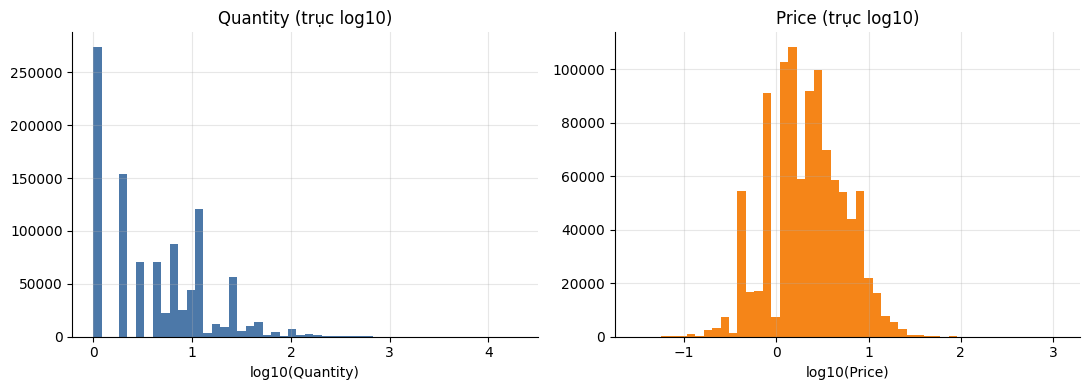

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].hist(np.log10(sales.Quantity), bins=50, color="#4C78A8"); ax[0].set_title("Quantity (trục log10)")
ax[0].set_xlabel("log10(Quantity)")
ax[1].hist(np.log10(sales.Price), bins=50, color="#F58518"); ax[1].set_title("Price (trục log10)")
ax[1].set_xlabel("log10(Price)")
save("03_phan_phoi_quantity_price")

In [15]:
# Các giá trị cực lớn: lỗi nhập liệu hay đơn sỉ thật?
big = df[(df.Quantity.abs() >= 10000) | (df.Price.abs() >= 10000)]
big[["Invoice", "StockCode", "Description", "Quantity", "InvoiceDate", "Price", "CustomerID"]]

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,CustomerID
90857,497946,37410,BLACK AND WHITE PAISLEY FLOWER MUG,19152,2010-02-15 11:57:00,0.10,"13,902.00"
127166,501534,21099,SET/6 STRAWBERRY PAPER CUPS,12960,2010-03-17 13:09:00,0.10,"13,902.00"
127167,501534,21092,SET/6 STRAWBERRY PAPER PLATES,12480,2010-03-17 13:09:00,0.10,"13,902.00"
127168,501534,21091,SET/6 WOODLAND PAPER PLATES,12960,2010-03-17 13:09:00,0.10,"13,902.00"
127169,501534,21085,SET/6 WOODLAND PAPER CUPS,12744,2010-03-17 13:09:00,0.10,"13,902.00"
135012,C502262,M,Manual,-1,2010-03-23 15:20:00,"10,953.50","12,918.00"
135013,502263,M,Manual,1,2010-03-23 15:22:00,"10,953.50","12,918.00"
135014,C502264,M,Manual,-1,2010-03-23 15:24:00,"10,953.50","12,918.00"
135015,502265,M,Manual,1,2010-03-23 15:28:00,"10,953.50",NaN
135027,502269,21984,PACK OF 12 PINK PAISLEY TISSUES,10000,2010-03-23 15:36:00,0.25,"17,940.00"


**Nhận xét:** Không nên dùng phương pháp IQR để loại bỏ ngoại lai vì phần lớn số lượng lớn là đơn bán sỉ hợp lệ hoặc cặp mua-hủy, thay vào đó nên xử lý bằng luật nghiệp vụ.

## 3. Đặc điểm Kinh doanh & Mùa vụ

### 3.1 Xu hướng theo thời gian

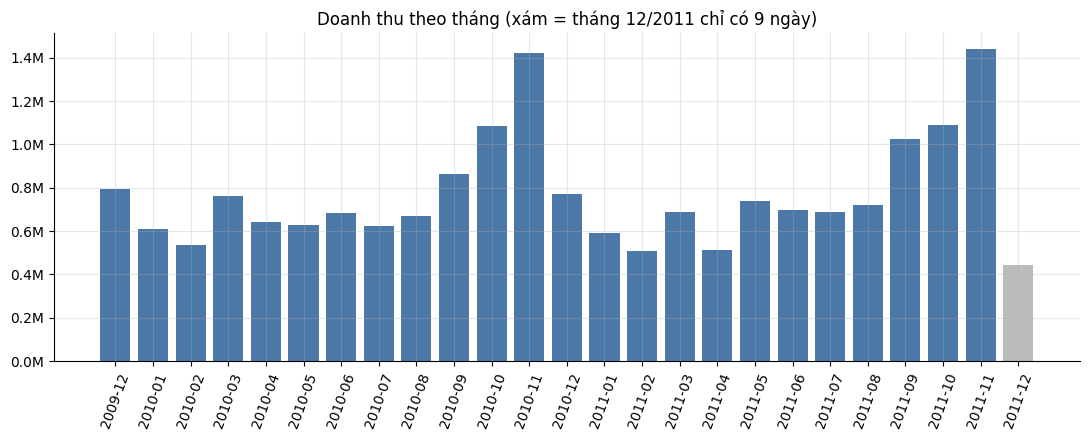

In [20]:
fig, ax = plt.subplots(figsize=(11, 4.5))
colors = ["#BBBBBB" if str(m) == "2011-12" else "#4C78A8" for m in monthly.index]
ax.bar(monthly.index.astype(str), monthly.doanh_thu, color=colors)
ax.set_title("Doanh thu theo tháng (xám = tháng 12/2011 chỉ có 9 ngày)")
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"{x/1e6:.1f}M"))
plt.xticks(rotation=70)
save("04_doanh_thu_theo_thang")

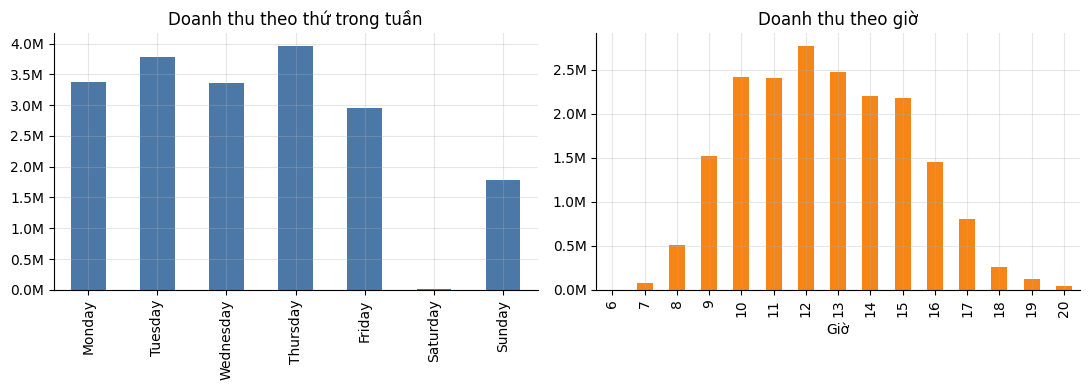

,doanh_thu,so_hoa_don
Weekday,,
Monday,"3,384,313.12",6215
Tuesday,"3,785,247.78",7121
Wednesday,"3,365,090.26",7089
Thursday,"3,968,556.48",8140
Friday,"2,946,478.25",5964
Saturday,"9,803.05",30
Sunday,"1,779,059.97",4815


In [21]:
# Theo thứ trong tuần và theo giờ
sales["Weekday"] = sales.InvoiceDate.dt.day_name()
sales["Hour"] = sales.InvoiceDate.dt.hour
order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
wd = sales.groupby("Weekday").agg(doanh_thu=("Revenue", "sum"), so_hoa_don=("Invoice", "nunique")).reindex(order)
hr = sales.groupby("Hour").Revenue.sum()

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
wd.doanh_thu.fillna(0).plot.bar(ax=ax[0], color="#4C78A8"); ax[0].set_title("Doanh thu theo thứ trong tuần")
ax[0].set_xlabel(""); ax[0].yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"{x/1e6:.1f}M"))
hr.plot.bar(ax=ax[1], color="#F58518"); ax[1].set_title("Doanh thu theo giờ"); ax[1].set_xlabel("Giờ")
ax[1].yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"{x/1e6:.1f}M"))
save("04_thu_gio")
wd

**Nhận xét:** Doanh thu mang tính mùa vụ, bắt đầu tăng từ tháng 9, đạt đỉnh vào tháng 11 và giảm mạnh vào đầu năm sau

### 3.2 Phân tích theo quốc gia

In [22]:
ctry = sales.groupby("Country").agg(doanh_thu=("Revenue", "sum"), so_hoa_don=("Invoice", "nunique"),
                                    so_khach=("CustomerID", "nunique"))
ctry["ti_trong_%"] = ctry.doanh_thu / ctry.doanh_thu.sum() * 100
ctry["gia_tri_don_TB"] = ctry.doanh_thu / ctry.so_hoa_don
ctry = ctry.sort_values("doanh_thu", ascending=False)
print("Số quốc gia:", len(ctry))
ctry.head(10)

Số quốc gia: 43


,doanh_thu,so_hoa_don,so_khach,ti_trong_%,gia_tri_don_TB
Country,,,,,
United Kingdom,"16,409,000.97",36067,5333,85.29,454.96
EIRE,"614,228.72",578,3,3.19,"1,062.68"
Netherlands,"549,773.41",216,22,2.86,"2,545.25"
Germany,"383,169.10",753,107,1.99,508.86
France,"309,853.49",595,93,1.61,520.76
Australia,"167,423.41",85,15,0.87,"1,969.69"
Spain,"97,766.75",144,38,0.51,678.94
Switzerland,"93,629.44",82,22,0.49,"1,141.82"
Sweden,"86,081.14",98,19,0.45,878.38


**Nhận xét:** Thị trường Anh chiếm 85% doanh thu, trong khi các nước như Hà Lan hay EIRE có số lượng khách rất ít nhưng giá trị đơn hàng trung bình lại rất cao.

## 4. Hành vi Khách hàng & Phân bổ Sản phẩm

### 4.1 Phân tích sản phẩm

In [24]:
canon = df.dropna(subset=["Description"]).groupby("StockCode").Description.agg(lambda s: s.mode().iat[0])
prod = sales.groupby("StockCode").agg(doanh_thu=("Revenue", "sum"), so_luong=("Quantity", "sum"),
                                      so_hoa_don=("Invoice", "nunique"))
prod["mo_ta"] = canon.reindex(prod.index)
prod = prod.sort_values("doanh_thu", ascending=False)

print("Số sản phẩm có doanh thu:", len(prod))
top20 = int(len(prod) * 0.2)
print("20% sản phẩm hàng đầu chiếm", round(prod.doanh_thu.head(top20).sum() / prod.doanh_thu.sum() * 100, 1), "% doanh thu")
prod.head(10)[["mo_ta", "doanh_thu", "so_luong", "so_hoa_don"]]

Số sản phẩm có doanh thu: 4873
20% sản phẩm hàng đầu chiếm 78.2 % doanh thu


,mo_ta,doanh_thu,so_luong,so_hoa_don
StockCode,,,,
22423,REGENCY CAKESTAND 3 TIER,"328,434.22",26288,3902
85123A,WHITE HANGING HEART T-LIGHT HOLDER,"255,353.51",93275,5361
85099B,JUMBO BAG RED RETROSPOT,"179,043.91",95891,3978
47566,PARTY BUNTING,"148,270.58",28190,2672
84879,ASSORTED COLOUR BIRD ORNAMENT,"128,989.40",79861,2802
22086,PAPER CHAIN KIT 50'S CHRISTMAS,"116,818.69",34716,2010
79321,CHILLI LIGHTS,"80,002.93",15716,1130
22197,SMALL POPCORN HOLDER,"79,367.70",88289,2320
22386,JUMBO BAG PINK POLKADOT,"75,381.12",38907,2239


In [25]:
top_qty = prod.sort_values("so_luong", ascending=False).head(10)[["mo_ta", "so_luong", "doanh_thu"]]
top_qty

,mo_ta,so_luong,doanh_thu
StockCode,,,
84077,WORLD WAR 2 GLIDERS ASSTD DESIGNS,106043,"24,421.61"
85099B,JUMBO BAG RED RETROSPOT,95891,"179,043.91"
21212,PACK OF 72 RETROSPOT CAKE CASES,94740,"51,745.95"
85123A,WHITE HANGING HEART T-LIGHT HOLDER,93275,"255,353.51"
22197,SMALL POPCORN HOLDER,88289,"79,367.70"
84879,ASSORTED COLOUR BIRD ORNAMENT,79861,"128,989.40"
17003,BROCADE RING PURSE,70333,"14,758.86"
21977,PACK OF 60 PINK PAISLEY CAKE CASES,56013,"28,055.33"
84991,60 TEATIME FAIRY CAKE CASES,53956,"27,001.61"


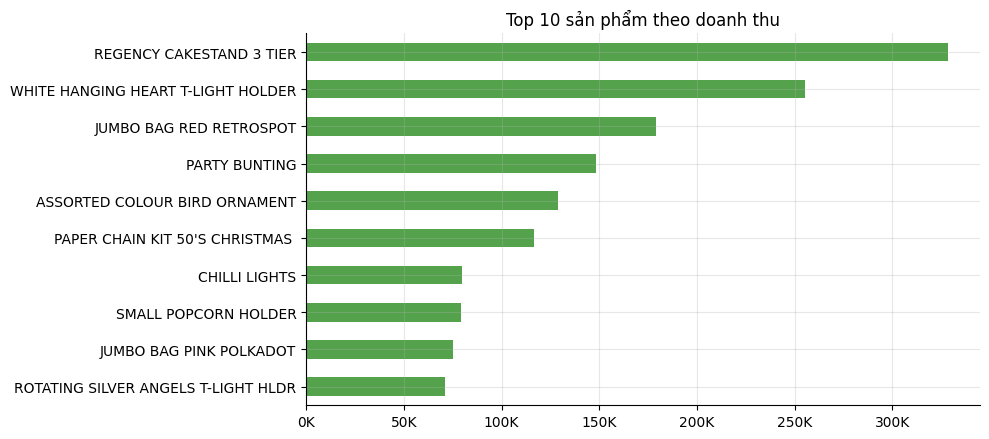

In [27]:
ax = prod.head(10).set_index("mo_ta").doanh_thu.sort_values().plot.barh(figsize=(10, 4.5), color="#54A24B")
ax.set_title("Top 10 sản phẩm theo doanh thu"); ax.set_ylabel("")
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"{x/1e3:.0f}K"))
save("06_top_san_pham")

**Nhận xét:** doanh thu tập trung vào một nhóm nhỏ sản phẩm (quy luật Pareto). Sản phẩm bán nhiều theo số lượng
không nhất thiết là sản phẩm tạo nhiều doanh thu nhất (khác nhau về giá).

### 4.2 Phân tích khách hàng (chỉ khách có Customer ID)

In [28]:
known = sales.dropna(subset=["CustomerID"]).copy()
known["CustomerID"] = known.CustomerID.astype(int)
cust = known.groupby("CustomerID").agg(doanh_thu=("Revenue", "sum"), so_hoa_don=("Invoice", "nunique"),
                                       ngay_dau=("InvoiceDate", "min"), ngay_cuoi=("InvoiceDate", "max"))
print("Số khách hàng:", len(cust))
cust[["doanh_thu", "so_hoa_don"]].describe(percentiles=[.5, .9, .99])

Số khách hàng: 5850


,doanh_thu,so_hoa_don
count,"5,850.00","5,850.00"
mean,"2,848.62",6.23
std,"13,979.36",12.67
min,2.90,1.00
50%,852.37,3.00
90%,"5,347.04",13.00
99%,"26,784.88",45.51
max,"579,704.64",371.00


Top  1% khách hàng chiếm  31.1% doanh thu
Top  5% khách hàng chiếm  51.1% doanh thu
Top 10% khách hàng chiếm  63.2% doanh thu
Top 20% khách hàng chiếm  76.7% doanh thu


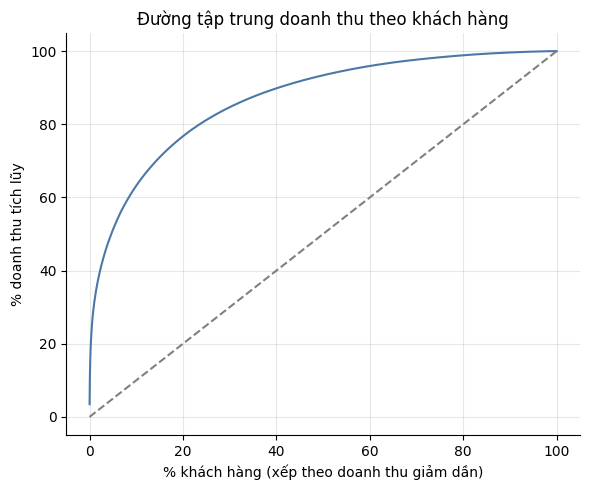

In [29]:
# Quy luật Pareto trên khách hàng
c = cust.doanh_thu.sort_values(ascending=False)
share = c.cumsum() / c.sum()
for p in (0.01, 0.05, 0.10, 0.20):
    print(f"Top {int(p*100):>2}% khách hàng chiếm {share.iloc[int(len(c)*p) - 1]*100:5.1f}% doanh thu")

fig, ax = plt.subplots(figsize=(6, 5))
ax.plot(np.arange(1, len(c) + 1) / len(c) * 100, share.values * 100, color="#4C78A8")
ax.plot([0, 100], [0, 100], "--", color="gray")
ax.set_xlabel("% khách hàng (xếp theo doanh thu giảm dần)"); ax.set_ylabel("% doanh thu tích lũy")
ax.set_title("Đường tập trung doanh thu theo khách hàng")
save("07_pareto_khach_hang")

Khách chỉ có 1 hóa đơn: 27.71 %
Khách có >= 2 hóa đơn: 72.29 %


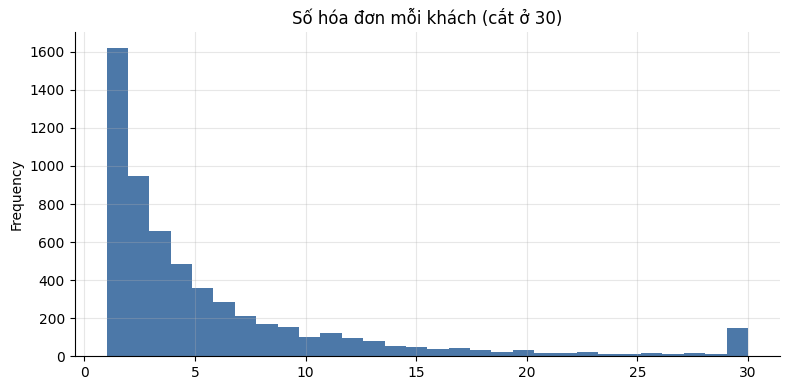

In [30]:
print("Khách chỉ có 1 hóa đơn:", pct((cust.so_hoa_don == 1).sum(), len(cust)), "%")
print("Khách có >= 2 hóa đơn:", pct((cust.so_hoa_don >= 2).sum(), len(cust)), "%")
cust.so_hoa_don.clip(upper=30).plot.hist(bins=30, color="#4C78A8", figsize=(8, 4), title="Số hóa đơn mỗi khách (cắt ở 30)")
save("07_so_hoa_don_moi_khach")

0.50    32.00
0.75    71.00
0.80    88.00
0.90   148.00
0.95   221.00
0.99   377.00


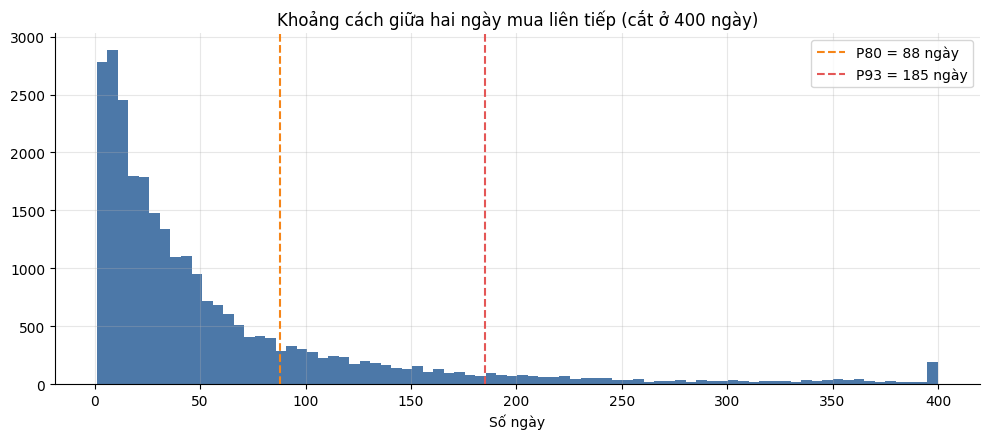

In [31]:
# Khoảng cách giữa hai lần mua: cơ sở để chọn ngưỡng churn
days = known[["CustomerID", "InvoiceDate"]].assign(d=lambda x: x.InvoiceDate.dt.normalize())[["CustomerID", "d"]]
days = days.drop_duplicates().sort_values(["CustomerID", "d"])
gaps = days.groupby("CustomerID").d.diff().dt.days.dropna()
gq = gaps.quantile([.5, .75, .8, .9, .95, .99])
print(gq.round(0).to_string())

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.hist(gaps.clip(upper=400), bins=80, color="#4C78A8")
for p, col in [(.8, "#F58518"), (.93, "#E45756")]:
    v = gaps.quantile(p); ax.axvline(v, color=col, ls="--", label=f"P{int(p*100)} = {v:.0f} ngày")
ax.set_title("Khoảng cách giữa hai ngày mua liên tiếp (cắt ở 400 ngày)")
ax.set_xlabel("Số ngày"); ax.legend()
save("07_khoang_cach_giua_2_lan_mua")

**Nhận xét** Dữ liệu cho thấy doanh thu phụ thuộc mạnh vào nhóm khách VIP (20% khách hàng đóng góp 76,7% doanh thu) và tỷ lệ giữ chân khá tốt khi 72,29% khách có từ 2 hóa đơn trở lên. Dựa trên chu kỳ mua sắm với trung vị 32 ngày và P90 là 148 ngày, việc đặt ngưỡng cảnh báo rời bỏ (churn) ở mức 90 hoặc 180 ngày là hợp lý để tránh gán nhãn sai cho những khách hàng có thói quen mua thưa thớt.

### 4.3 Đơn hoàn/hủy

Giá trị hủy/hoàn = 3.7% doanh thu gộp
Số khách có ít nhất một đơn hủy: 2444 (41.8% khách hàng)


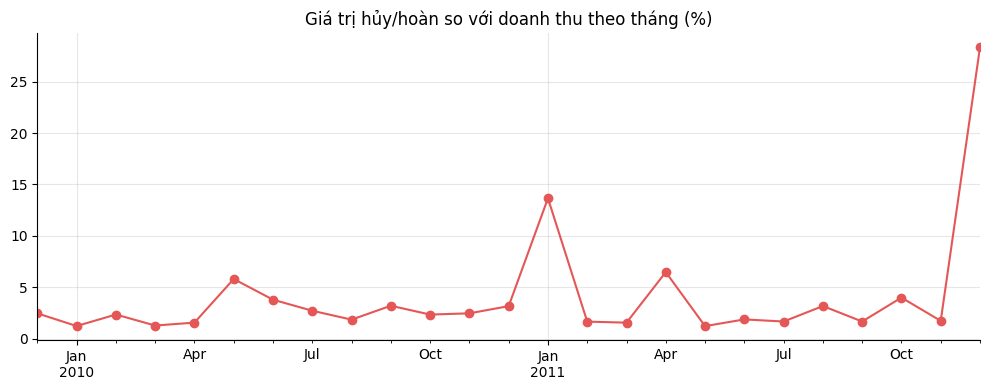

In [33]:
cancel = df[is_cancel & is_product & (df.Price > 0)].copy()
cancel["Value"] = (cancel.Quantity * cancel.Price).abs()
cancel["Month"] = cancel.InvoiceDate.dt.to_period("M")

# Mẫu số = doanh thu gộp (cộng lại các dòng bán đã bị ghép cặp hủy ở phần 3)
gross = monthly.doanh_thu + removed.groupby("Month").Revenue.sum().reindex(monthly.index).fillna(0)
cm = pd.DataFrame({"gia_tri_huy": cancel.groupby("Month").Value.sum(), "doanh_thu_gop": gross}).dropna()
cm["ti_le_huy_%"] = cm.gia_tri_huy / cm.doanh_thu_gop * 100
print(f"Giá trị hủy/hoàn = {cancel.Value.sum() / gross.sum() * 100:.1f}% doanh thu gộp")
print("Số khách có ít nhất một đơn hủy:", cancel.CustomerID.nunique(),
      f"({cancel.CustomerID.nunique() / len(cust) * 100:.1f}% khách hàng)")
cm["ti_le_huy_%"].plot(figsize=(10, 4), marker="o", color="#E45756", title="Giá trị hủy/hoàn so với doanh thu theo tháng (%)")
plt.xlabel("")
save("08_ti_le_huy")

## 5. Tổng kết 

In [34]:
summary = pd.DataFrame([
    ("Dữ liệu thiếu Customer ID (~23% dòng)", "Tách luồng; loại khỏi mô hình churn; giữ cho phân tích doanh thu/sản phẩm"),
    ("Dòng trùng, Price ≤ 0, StockCode không phải sản phẩm", "Loại theo luật nghiệp vụ ở bước làm sạch "),
    ("Đơn hủy (C) và dòng Quantity < 0", "Tách thành bảng riêng, dùng làm đặc trưng hoàn/hủy, không tính là hoạt động mua"),
    ("Quantity/Price lệch phải rất mạnh, IQR gắn cờ quá nhiều", "Không dùng IQR để xóa; dùng log/winsorize ở cấp khách hàng"),
    ("Cặp mua–hủy cực lớn (±80.995)", "Ghép cặp và loại bỏ"),
    ("Mùa vụ mạnh (đỉnh Q4)", "Định nghĩa churn cần tính mùa vụ; so sánh cùng kỳ"),
    ("Doanh thu tập trung vào ít khách hàng/sản phẩm", "Phân khúc phải nhận diện nhóm tạo doanh thu chính; ưu tiên chăm sóc theo giá trị"),
    ("Khoảng cách giữa hai lần mua dài (P80 ≈ 88 ngày)", "Thử cả hai ngưỡng churn 90 và 180 ngày"),
    ("Dữ liệu 12/2009 và 12/2011 không đủ tháng", "Chọn cutoff phù hợp, tránh quý/tháng không đầy đủ khi so sánh"),
], columns=["phat_hien", "huong_xu_ly"])
summary

,phat_hien,huong_xu_ly
0,Dữ liệu thiếu Customer ID (~23% dòng),Tách luồng; loại khỏi mô hình churn; giữ cho p...
1,"Dòng trùng, Price ≤ 0, StockCode không phải sả...",Loại theo luật nghiệp vụ ở bước làm sạch
2,Đơn hủy (C) và dòng Quantity < 0,"Tách thành bảng riêng, dùng làm đặc trưng hoàn..."
3,"Quantity/Price lệch phải rất mạnh, IQR gắn cờ ...",Không dùng IQR để xóa; dùng log/winsorize ở cấ...
4,Cặp mua–hủy cực lớn (±80.995),Ghép cặp và loại bỏ
5,Mùa vụ mạnh (đỉnh Q4),Định nghĩa churn cần tính mùa vụ; so sánh cùng kỳ
6,Doanh thu tập trung vào ít khách hàng/sản phẩm,Phân khúc phải nhận diện nhóm tạo doanh thu ch...
7,Khoảng cách giữa hai lần mua dài (P80 ≈ 88 ngày),Thử cả hai ngưỡng churn 90 và 180 ngày
8,Dữ liệu 12/2009 và 12/2011 không đủ tháng,"Chọn cutoff phù hợp, tránh quý/tháng không đầy..."
